In [1]:
!pip install pymoo matplotlib -q

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
class EVBatteryProblem(ElementwiseProblem):

    def __init__(self):
        super().__init__(
            n_var=2,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.array([10.0, 15.0]),
            xu=np.array([150.0, 45.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):

        potencia = x[0]
        temp = x[1]

        # Objetivo 1: Minimizar tempo de recarga
        f1_tempo_recarga = 3000.0 / potencia

        # Objetivo 2: Minimizar desgaste da bateria
        f2_desgaste_bateria = (potencia ** 1.5) * (temp / 20.0)

        # Restrição: desgaste máximo de 1500
        g1 = f2_desgaste_bateria - 1500.0

        out["F"] = [f1_tempo_recarga, f2_desgaste_bateria]
        out["G"] = [g1]


print("Problema de bateria criado com sucesso!")

Problema de bateria criado com sucesso!


In [4]:
res6 = minimize(
    EVBatteryProblem(),
    NSGA2(pop_size=50),
    termination=('n_gen', 80),
    seed=6
)

print("Otimização das baterias concluída!")

Otimização das baterias concluída!


In [5]:
print("RESULTADOS DO EXERCÍCIO 6")
print("=" * 50)

for i in range(len(res6.F)):

    potencia = res6.X[i, 0]
    temperatura = res6.X[i, 1]

    tempo = res6.F[i, 0]
    desgaste = res6.F[i, 1]

    if desgaste <= 1500:

        print(f"Solução {i+1}")
        print(f"Potência: {potencia:.2f} kW")
        print(f"Temperatura: {temperatura:.2f} °C")
        print(f"Tempo de recarga: {tempo:.2f}")
        print(f"Desgaste: {desgaste:.2f}")
        print("Status: VIÁVEL")
        print("-" * 30)

RESULTADOS DO EXERCÍCIO 6
Solução 1
Potência: 10.00 kW
Temperatura: 15.00 °C
Tempo de recarga: 300.00
Desgaste: 23.72
Status: VIÁVEL
------------------------------
Solução 2
Potência: 150.00 kW
Temperatura: 15.00 °C
Tempo de recarga: 20.00
Desgaste: 1377.84
Status: VIÁVEL
------------------------------
Solução 3
Potência: 10.86 kW
Temperatura: 15.12 °C
Tempo de recarga: 276.34
Desgaste: 27.03
Status: VIÁVEL
------------------------------
Solução 4
Potência: 34.03 kW
Temperatura: 15.00 °C
Tempo de recarga: 88.16
Desgaste: 148.88
Status: VIÁVEL
------------------------------
Solução 5
Potência: 122.63 kW
Temperatura: 15.00 °C
Tempo de recarga: 24.46
Desgaste: 1018.54
Status: VIÁVEL
------------------------------
Solução 6
Potência: 12.84 kW
Temperatura: 15.00 °C
Tempo de recarga: 233.57
Desgaste: 34.52
Status: VIÁVEL
------------------------------
Solução 7
Potência: 130.44 kW
Temperatura: 15.00 °C
Tempo de recarga: 23.00
Desgaste: 1117.27
Status: VIÁVEL
------------------------------
So

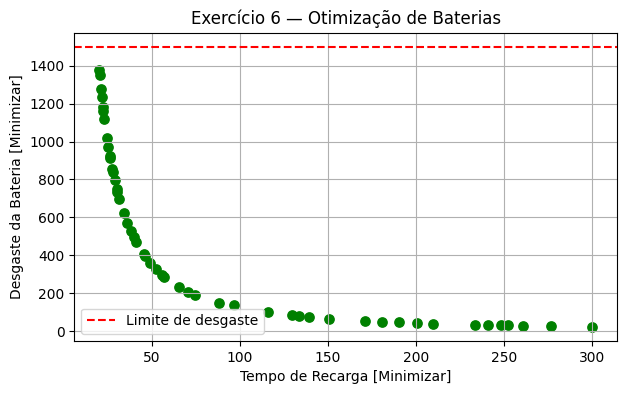

In [6]:
viaveis = res6.F[res6.F[:, 1] <= 1500]

plt.figure(figsize=(7, 4))

plt.scatter(
    viaveis[:, 0],
    viaveis[:, 1],
    color='green',
    s=45
)

plt.axhline(
    y=1500,
    color='red',
    linestyle='--',
    label='Limite de desgaste'
)

plt.title("Exercício 6 — Otimização de Baterias")
plt.xlabel("Tempo de Recarga [Minimizar]")
plt.ylabel("Desgaste da Bateria [Minimizar]")

plt.legend()
plt.grid(True)
plt.show()